# Component Degradation Modelling with Bayesian Hierarchical Models

Mechanical component *K* loses integrity (0-100%) over time. Integrity was measured irregularly for 75 components, but the 25 most recently commissioned ones have very few observations. This notebook fits two hierarchical Bayesian exponential-decay models with HMC/NUTS (`numpyro`) and uses them to forecast the sparse components.

**Contents**
1. Load and explore the data
2. Baseline model: $f_i(t) = u_i \exp\{-v_i\, t/100\}$
3. Enhanced model, adding component characteristics: $f_i(t) = u_i \exp\{-(v_i + \sum_j w_j x_{ji})\, t/100\}$
4. Blind-test predictions: $P(\text{integrity} \le 30 \text{ at } t=30)$ for components 50-74
5. Saving posterior samples for the deployable predictor (`03_deployable_predictor.ipynb`)
6. Additional figures

Run from the `notebooks/` directory. Figures are written to `../docs/figures/` and results to `../results/`.

In [ ]:
# Dependencies: see requirements.txt (numpyro, arviz, pandas, seaborn, matplotlib, scipy)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as sp_stats

import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az

jax.config.update('jax_platforms', 'cpu')
numpyro.set_host_device_count(4)
plt.style.use('bmh')

print(f"numpyro version: {numpyro.__version__}")

numpyro version: 0.20.1


## 1. Load and Explore Data

In [3]:
df = pd.read_csv('../data/bml-component-data.csv')
print(f"Dataset: {df.shape[0]} measurements across {df['index'].nunique()} components")
print(f"Columns: {list(df.columns)}")
df.head(10)

Dataset: 879 measurements across 75 components
Columns: ['ID', 'index', 'X1', 'X2', 'X3', 'X4', 'X5', 'day', 'integrity']


,ID,index,X1,X2,X3,X4,X5,day,integrity
0,K#0000,0,1.897,1.111,0.585,1.436,3.684,1.0,94.203
1,K#0000,0,1.897,1.111,0.585,1.436,3.684,3.0,90.663
2,K#0000,0,1.897,1.111,0.585,1.436,3.684,5.0,76.650
3,K#0000,0,1.897,1.111,0.585,1.436,3.684,7.0,74.893
4,K#0000,0,1.897,1.111,0.585,1.436,3.684,8.0,73.923
5,K#0000,0,1.897,1.111,0.585,1.436,3.684,9.0,68.215
6,K#0000,0,1.897,1.111,0.585,1.436,3.684,10.0,80.775
7,K#0000,0,1.897,1.111,0.585,1.436,3.684,11.0,67.666
8,K#0000,0,1.897,1.111,0.585,1.436,3.684,13.0,68.079
9,K#0000,0,1.897,1.111,0.585,1.436,3.684,14.0,63.360


In [4]:
# Key constants
n_components = 75
n_train_components = 50
n_test_components = 25
test_indices = list(range(50, 75))

# Data arrays for numpyro
component_idx = df['index'].values
day = df['day'].values
integrity = df['integrity'].values

# Component characteristics (constant per component)
X_features = df.groupby('index')[['X1','X2','X3','X4','X5']].first().values  # (75, 5)

# Per-observation feature matrix
X_obs = df[['X1','X2','X3','X4','X5']].values  # (879, 5)

# Measurements per component
counts = df.groupby('index').size()
print(f"Measurements per component (first 50): mean={counts[:50].mean():.1f}, range=[{counts[:50].min()}, {counts[:50].max()}]")
print(f"Measurements per component (last 25):  mean={counts[50:].mean():.1f}, range=[{counts[50:].min()}, {counts[50:].max()}]")

Measurements per component (first 50): mean=16.1, range=[1, 41]
Measurements per component (last 25):  mean=3.0, range=[1, 8]


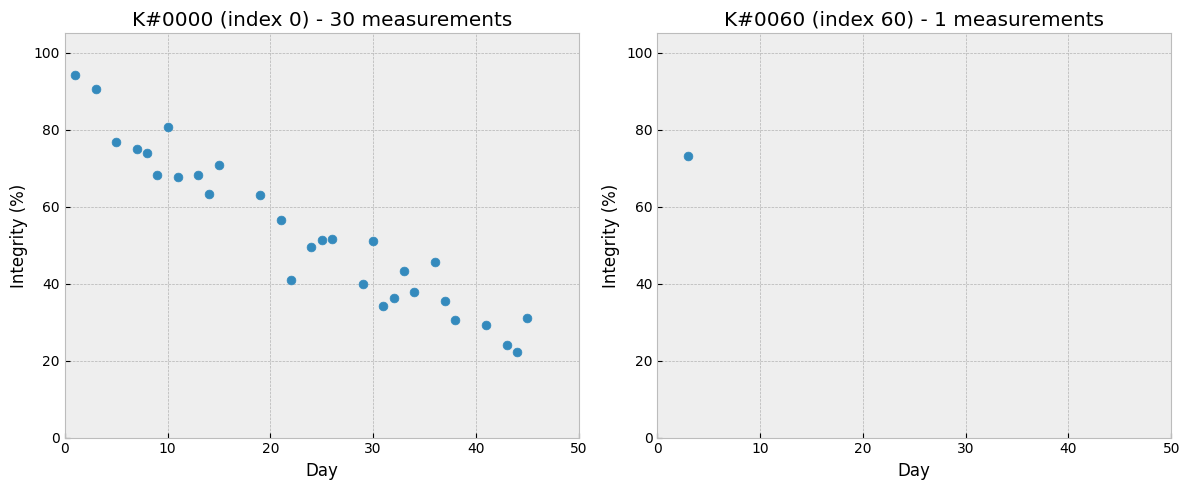

In [5]:
# Visualise a few components
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# One data-rich component
comp0 = df[df['index'] == 0]
axes[0].scatter(comp0['day'], comp0['integrity'], s=40, zorder=5)
axes[0].set_xlabel('Day'); axes[0].set_ylabel('Integrity (%)')
axes[0].set_title(f"K#0000 (index 0) - {len(comp0)} measurements")
axes[0].set_xlim(0, 50); axes[0].set_ylim(0, 105)

# One data-sparse component
comp60 = df[df['index'] == 60]
axes[1].scatter(comp60['day'], comp60['integrity'], s=40, zorder=5)
axes[1].set_xlabel('Day'); axes[1].set_ylabel('Integrity (%)')
axes[1].set_title(f"K#0060 (index 60) - {len(comp60)} measurements")
axes[1].set_xlim(0, 50); axes[1].set_ylim(0, 105)

plt.tight_layout()
plt.savefig('../docs/figures/fig_data_examples.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2. Baseline Model (Equation 1)

$$f_i(t) = u_i \exp\{-v_i\, t/100\}$$

Hierarchical structure:
- $u_i \sim N(\mu_u, \sigma_u)$ for each component
- $v_i \sim N(\mu_v, \sigma_v)$ for each component
- Hyperpriors on $\mu_u, \sigma_u, \mu_v, \sigma_v$
- Observation noise $\sigma_y$

Using **non-centred parameterisation** (reparameterisation) for better sampling.

In [6]:
def baseline_model(n_components, component_idx, t, y=None):
    """
    Baseline hierarchical model: y_i(t) = u_i * exp(-v_i * t / 100) + noise
    Uses non-centred parameterisation for u_i and v_i.
    """
    # Hyperpriors for u (intercept ~ 80-100)
    mu_u = numpyro.sample("mu_u", dist.Normal(90.0, 10.0))
    sigma_u = numpyro.sample("sigma_u", dist.HalfNormal(10.0))

    # Hyperpriors for v (decay rate ~ 1-10)
    mu_v = numpyro.sample("mu_v", dist.Normal(5.0, 5.0))
    sigma_v = numpyro.sample("sigma_v", dist.HalfNormal(5.0))

    # Non-centred parameterisation for u_i and v_i
    with numpyro.plate("components", n_components):
        u_raw = numpyro.sample("u_raw", dist.Normal(0.0, 1.0))
        v_raw = numpyro.sample("v_raw", dist.Normal(0.0, 1.0))

    u = numpyro.deterministic("u_i", mu_u + sigma_u * u_raw)
    v = numpyro.deterministic("v_i", mu_v + sigma_v * v_raw)

    # Observation noise
    sigma_y = numpyro.sample("sigma_y", dist.HalfNormal(10.0))

    # Predicted function: f_i(t) = u_i * exp(-v_i * t / 100)
    f = u[component_idx] * jnp.exp(-v[component_idx] * t / 100.0)

    # Observation model
    with numpyro.plate("obs", len(t)):
        numpyro.sample("y", dist.Normal(f, sigma_y), obs=y)

In [7]:
# Run MCMC for Baseline Model
num_warmup = 2000
num_samples = 2000
num_chains = 4

kernel_bl = NUTS(baseline_model)
mcmc_bl = MCMC(kernel_bl, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
rng_key = jax.random.PRNGKey(0)
mcmc_bl.run(rng_key, n_components, component_idx, day, y=integrity)
mcmc_bl.print_summary(exclude_deterministic=True)

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_u     89.72      0.87     89.73     88.30     91.12   5256.43      1.00
      mu_v      3.93      0.22      3.93      3.58      4.29   1120.10      1.00
   sigma_u      5.28      0.82      5.24      4.00      6.65   3723.43      1.00
   sigma_v      1.59      0.17      1.58      1.31      1.86   3150.02      1.00
   sigma_y      5.10      0.13      5.10      4.89      5.32  12380.36      1.00
  u_raw[0]      0.82      0.46      0.80      0.11      1.61  12888.40      1.00
  u_raw[1]     -0.45      0.82     -0.46     -1.85      0.83  13990.77      1.00
  u_raw[2]      1.70      0.47      1.68      0.91      2.44  10754.49      1.00
  u_raw[3]     -0.09      0.44     -0.09     -0.82      0.61  12549.72      1.00
  u_raw[4]     -0.49      0.74     -0.49     -1.74      0.70  15652.05      1.00
  u_raw[5]     -0.07      0.77     -0.08     -1.38      1.17  16219.97      1.00
  u_raw[6]      0.37      0

In [8]:
# Get samples
samples_bl = mcmc_bl.get_samples()
print("Baseline model samples:")
for key, val in samples_bl.items():
    print(f"  {key}: {val.shape}")

Baseline model samples:
  mu_u: (8000,)
  mu_v: (8000,)
  sigma_u: (8000,)
  sigma_v: (8000,)
  sigma_y: (8000,)
  u_i: (8000, 75)
  u_raw: (8000, 75)
  v_i: (8000, 75)
  v_raw: (8000, 75)


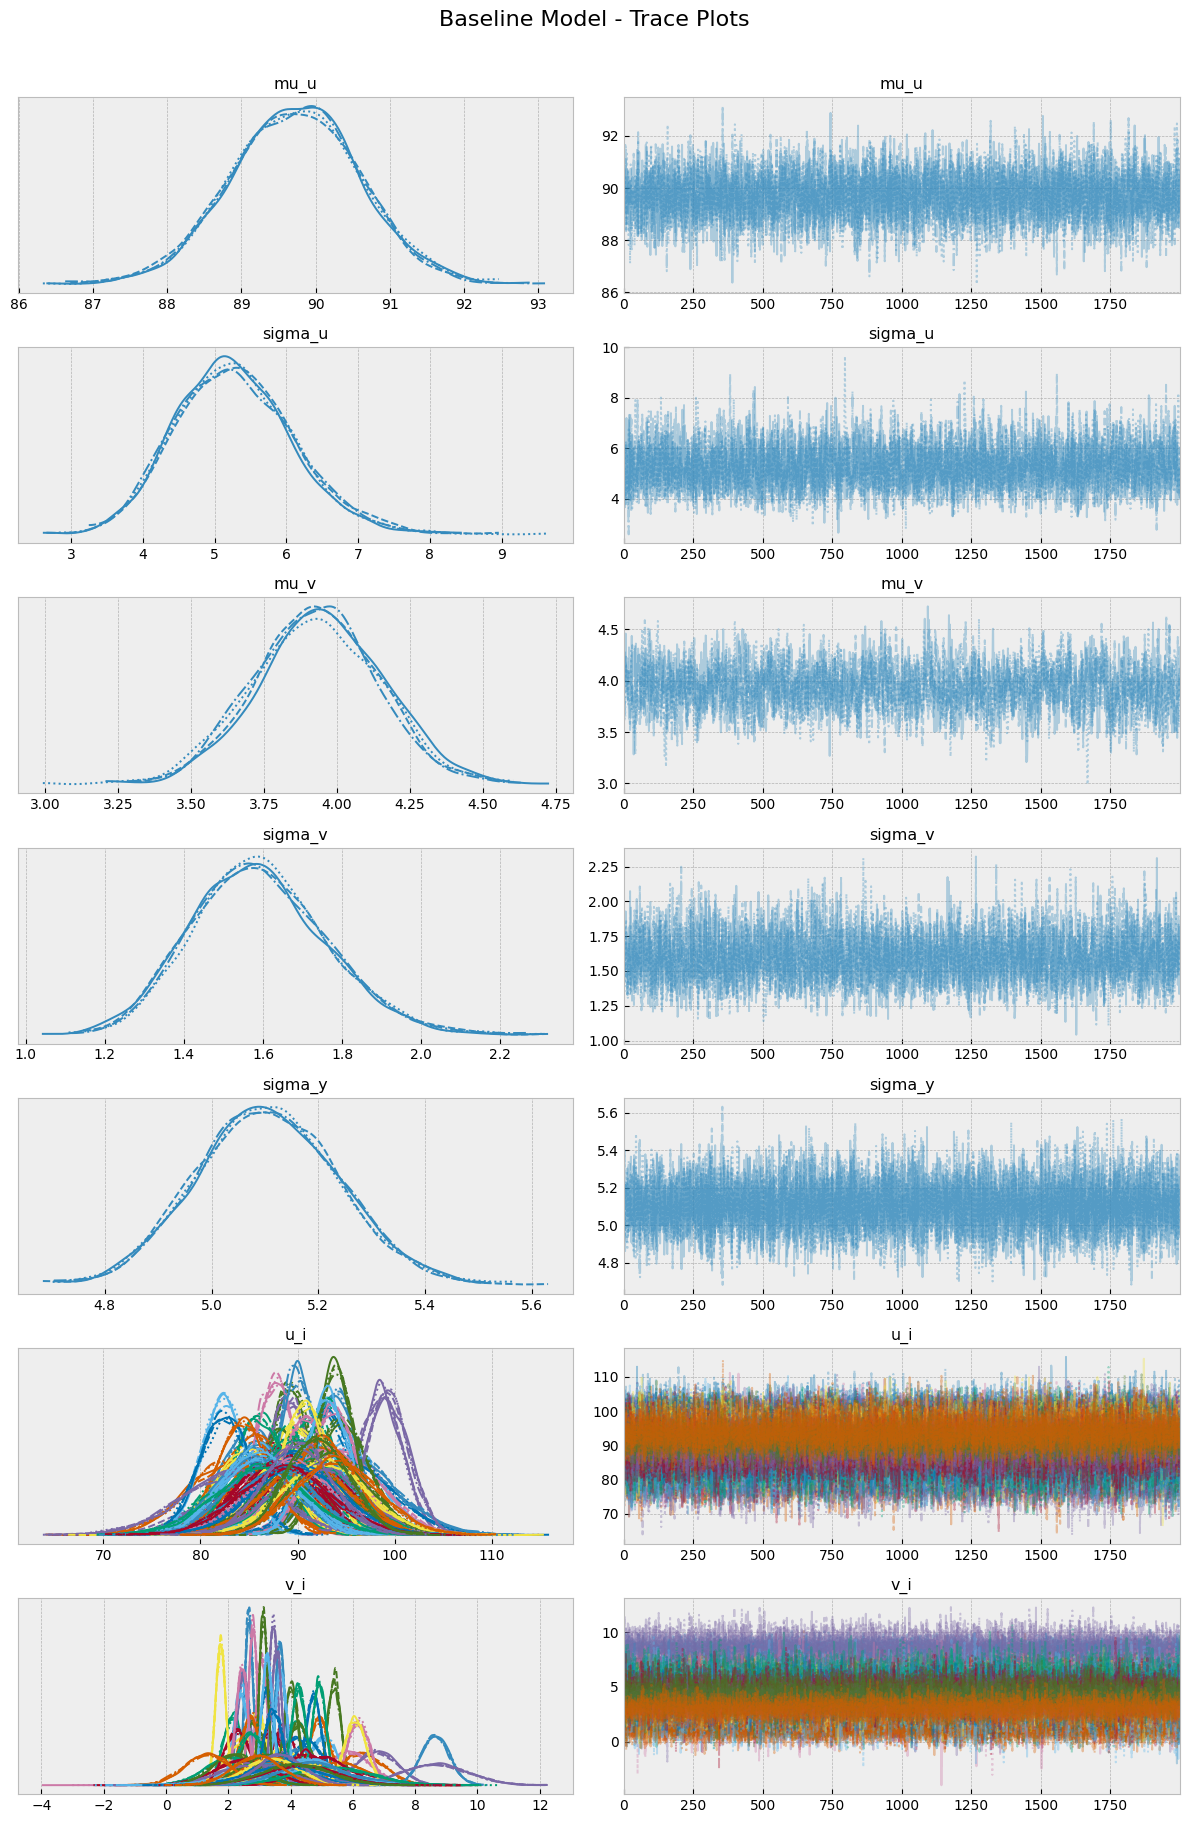

In [9]:
# Arviz trace plots for baseline model
az_bl = az.from_numpyro(mcmc_bl)

# Plot u_i, v_i (compact), hyperparameters, and sigma_y
az.plot_trace(az_bl, var_names=["mu_u", "sigma_u", "mu_v", "sigma_v", "sigma_y", "u_i", "v_i"],
              compact=True, figsize=(12, 18))
plt.suptitle("Baseline Model - Trace Plots", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('../docs/figures/fig_baseline_trace.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Prediction function for baseline model
def predict_baseline(component_idx, t_pred, samples):
    """
    Compute posterior predictive for a given component.
    Returns: f_mean, f_std (function only), f_std_with_noise
    """
    u_samples = samples["u_i"][:, component_idx]  # (n_samples,)
    v_samples = samples["v_i"][:, component_idx]
    sigma_y_samples = samples["sigma_y"]

    # t_pred can be array
    t_pred = jnp.array(t_pred).reshape(1, -1)  # (1, T)

    # f for each sample at each time
    F = u_samples.reshape(-1, 1) * jnp.exp(-v_samples.reshape(-1, 1) * t_pred / 100.0)  # (n_samples, T)

    f_mean = jnp.mean(F, axis=0)
    f_var = jnp.var(F, axis=0)
    f_std = jnp.sqrt(f_var)

    noise_var = jnp.mean(sigma_y_samples ** 2)
    f_std_noisy = jnp.sqrt(f_var + noise_var)

    return f_mean, f_std, f_std_noisy, F

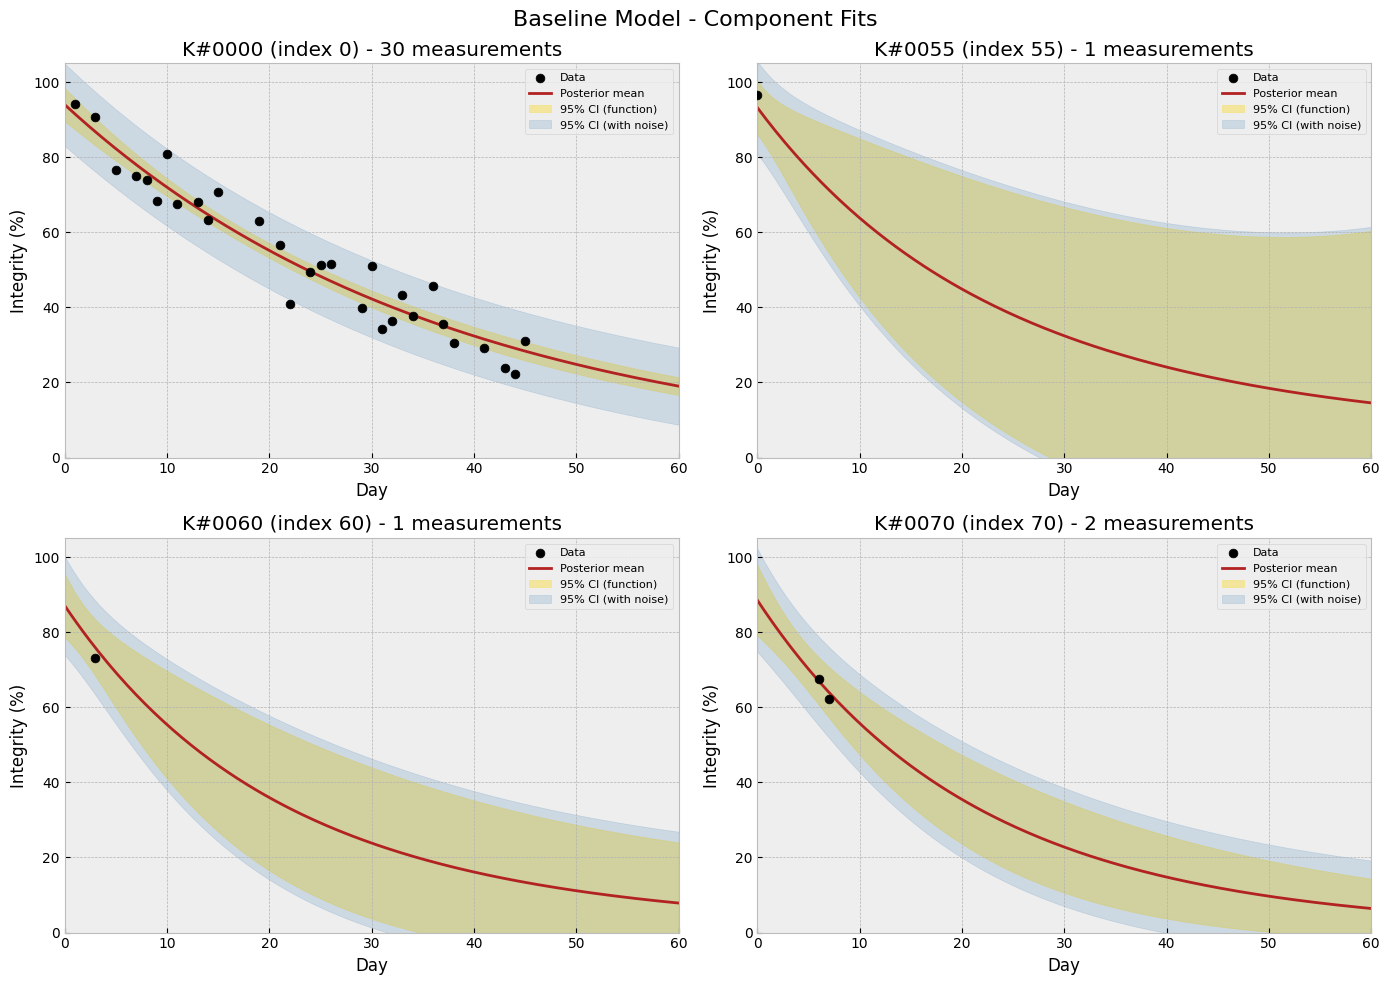

In [11]:
# Plot model fits for 4 components: 1 data-rich, 3 data-sparse
components_to_plot = [0, 55, 60, 70]  # 0=data-rich, rest=sparse
t_plot = np.linspace(0, 60, 200)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, comp_idx in zip(axes.ravel(), components_to_plot):
    # Data for this component
    comp_data = df[df['index'] == comp_idx]
    comp_id = comp_data['ID'].iloc[0]

    # Predictions
    f_mean, f_std, f_std_noisy, _ = predict_baseline(comp_idx, t_plot, samples_bl)

    # Plot
    ax.scatter(comp_data['day'], comp_data['integrity'], s=40, zorder=5,
               color='black', label='Data')
    ax.plot(t_plot, f_mean, color='firebrick', lw=2, label='Posterior mean')

    # Inner error bars: 1.96 * function std
    ax.fill_between(t_plot, f_mean - 1.96 * f_std, f_mean + 1.96 * f_std,
                    alpha=0.35, color='gold', label='95% CI (function)')
    # Outer error bars: 1.96 * noisy std
    ax.fill_between(t_plot, f_mean - 1.96 * f_std_noisy, f_mean + 1.96 * f_std_noisy,
                    alpha=0.2, color='steelblue', label='95% CI (with noise)')

    ax.set_xlim(0, 60); ax.set_ylim(0, 105)
    ax.set_xlabel('Day'); ax.set_ylabel('Integrity (%)')
    ax.set_title(f"{comp_id} (index {comp_idx}) - {len(comp_data)} measurements")
    ax.legend(fontsize=8)

plt.suptitle("Baseline Model - Component Fits", fontsize=16)
plt.tight_layout()
plt.savefig('../docs/figures/fig_baseline_fits.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3. Enhanced Model (Equation 2)

$$f_i(t) = u_i \exp\left\{-\left(v_i + \sum_{j=1}^{5} w_j x_{ji}\right) t/100\right\}$$

Same hierarchical structure for $u_i, v_i$, plus shared weights $w_j$ for component characteristics.

In [12]:
def enhanced_model(n_components, component_idx, t, X_obs, y=None):
    """
    Enhanced hierarchical model:
    y_i(t) = u_i * exp(-(v_i + sum_j w_j * x_ji) * t / 100) + noise
    Uses non-centred parameterisation.
    """
    # Hyperpriors for u (intercept)
    mu_u = numpyro.sample("mu_u", dist.Normal(90.0, 10.0))
    sigma_u = numpyro.sample("sigma_u", dist.HalfNormal(10.0))

    # Hyperpriors for v (decay rate — expected smaller due to w_j contribution)
    mu_v = numpyro.sample("mu_v", dist.Normal(2.0, 5.0))
    sigma_v = numpyro.sample("sigma_v", dist.HalfNormal(5.0))

    # Non-centred parameterisation for u_i and v_i
    with numpyro.plate("components", n_components):
        u_raw = numpyro.sample("u_raw", dist.Normal(0.0, 1.0))
        v_raw = numpyro.sample("v_raw", dist.Normal(0.0, 1.0))

    u = numpyro.deterministic("u_i", mu_u + sigma_u * u_raw)
    v = numpyro.deterministic("v_i", mu_v + sigma_v * v_raw)

    # Diagnostic weights w_j (shared across all components)
    sigma_w = numpyro.sample("sigma_w", dist.HalfNormal(2.0))
    with numpyro.plate("features", 5):
        w = numpyro.sample("w", dist.Normal(0.0, sigma_w))

    # Observation noise
    sigma_y = numpyro.sample("sigma_y", dist.HalfNormal(10.0))

    # Compute effective decay: v_i + sum_j(w_j * x_ji) for each observation
    wx = jnp.dot(X_obs, w)  # (N_obs,)
    effective_decay = v[component_idx] + wx

    # Predicted function
    f = u[component_idx] * jnp.exp(-effective_decay * t / 100.0)

    # Observation model
    with numpyro.plate("obs", len(t)):
        numpyro.sample("y", dist.Normal(f, sigma_y), obs=y)

In [13]:
# Run MCMC for Enhanced Model
kernel_en = NUTS(enhanced_model)
mcmc_en = MCMC(kernel_en, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains)
rng_key_en = jax.random.PRNGKey(1)
mcmc_en.run(rng_key_en, n_components, component_idx, day, X_obs, y=integrity)
mcmc_en.print_summary(exclude_deterministic=True)

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_u     90.34      0.79     90.34     89.04     91.63   3286.33      1.00
      mu_v      1.99      0.15      1.99      1.75      2.24   2482.41      1.00
   sigma_u      4.78      0.61      4.75      3.78      5.77   2887.78      1.00
   sigma_v      0.35      0.07      0.34      0.23      0.45   2701.23      1.00
   sigma_w      0.67      0.31      0.59      0.29      1.04   5784.86      1.00
   sigma_y      5.09      0.13      5.09      4.88      5.30   9198.63      1.00
  u_raw[0]      0.81      0.47      0.81      0.03      1.58   7300.16      1.00
  u_raw[1]      0.29      0.77      0.28     -1.01      1.52   8225.96      1.00
  u_raw[2]      1.70      0.48      1.68      0.94      2.51   5812.28      1.00
  u_raw[3]     -0.20      0.45     -0.20     -0.96      0.52   8290.86      1.00
  u_raw[4]     -0.14      0.68     -0.14     -1.24      1.02  10052.01      1.00
  u_raw[5]     -0.45      0

In [14]:
samples_en = mcmc_en.get_samples()
print("Enhanced model samples:")
for key, val in samples_en.items():
    print(f"  {key}: {val.shape}")

Enhanced model samples:
  mu_u: (8000,)
  mu_v: (8000,)
  sigma_u: (8000,)
  sigma_v: (8000,)
  sigma_w: (8000,)
  sigma_y: (8000,)
  u_i: (8000, 75)
  u_raw: (8000, 75)
  v_i: (8000, 75)
  v_raw: (8000, 75)
  w: (8000, 5)


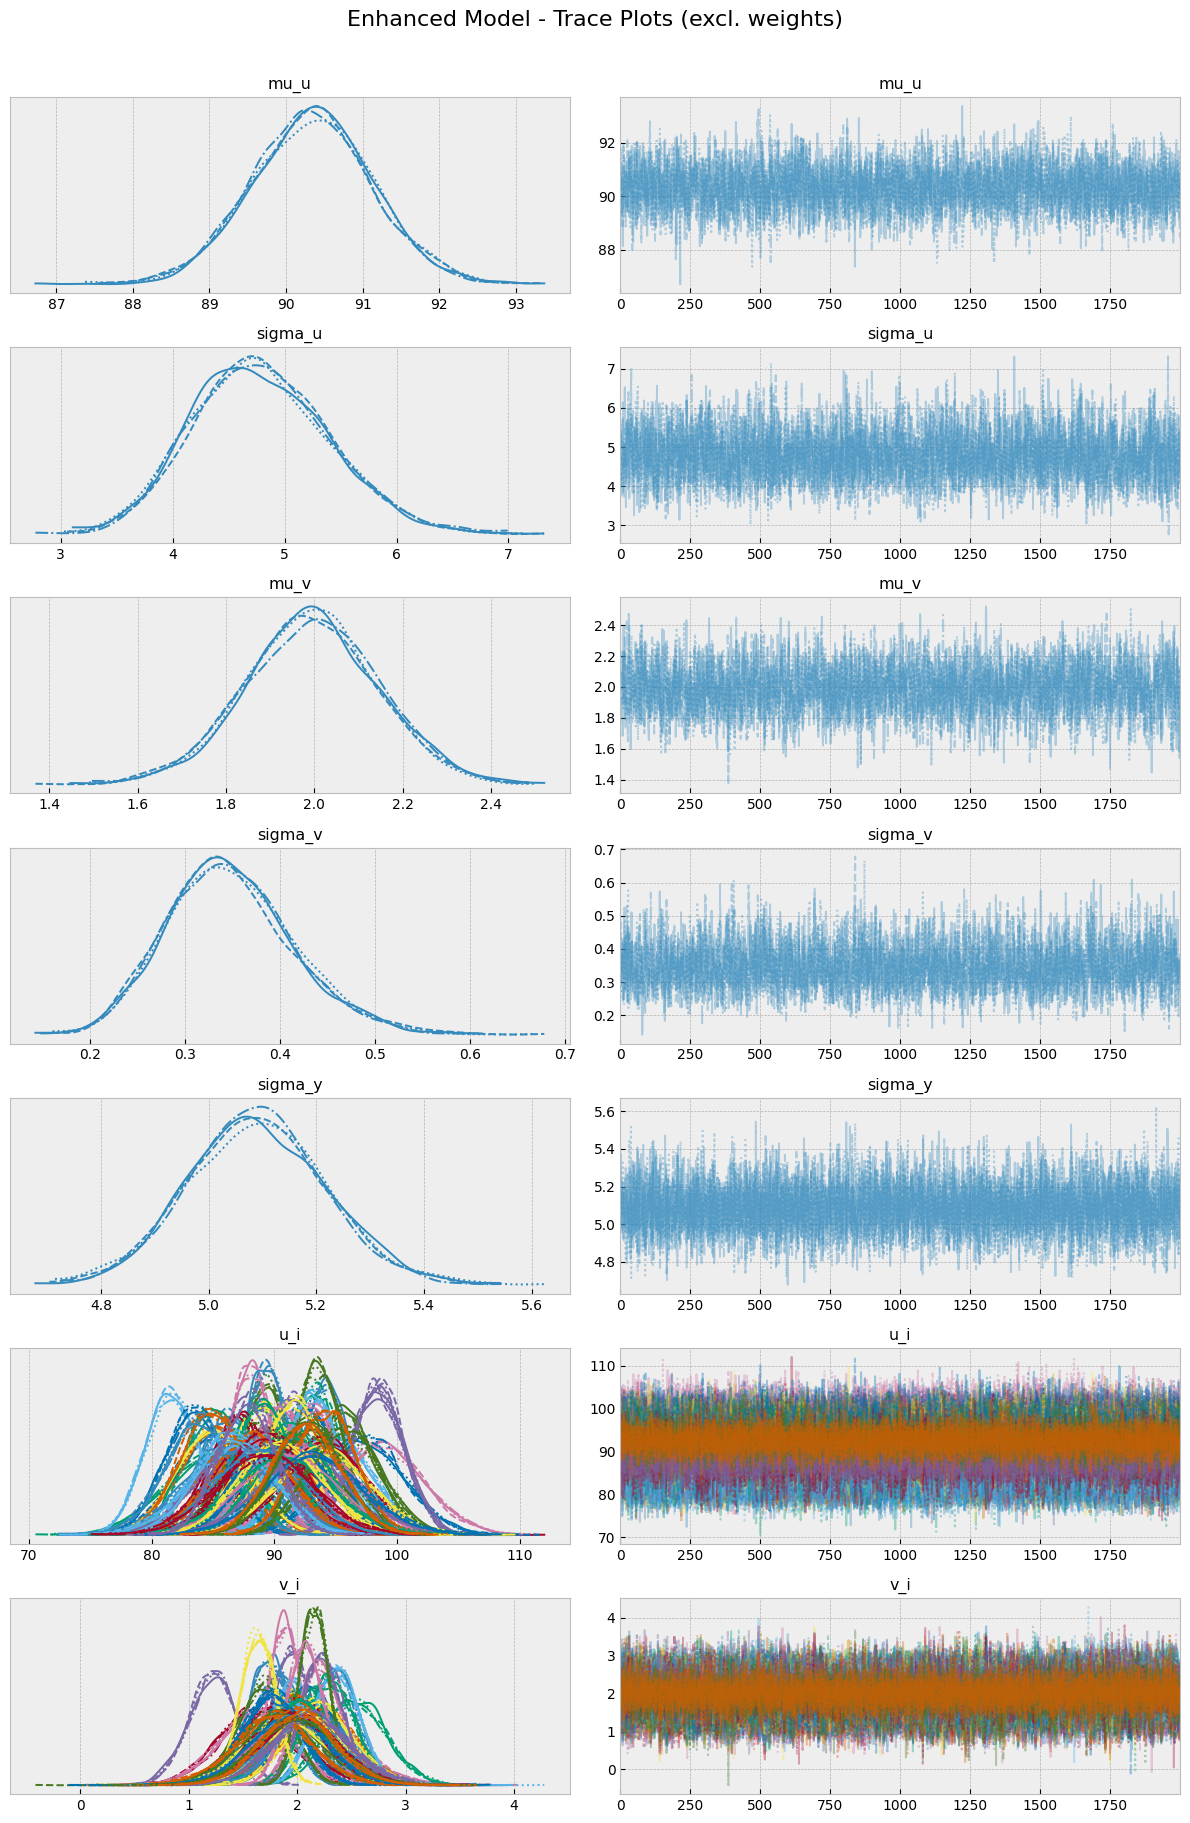

In [15]:
# Arviz trace plots for enhanced model - EXCLUDE w and sigma_w here
az_en = az.from_numpyro(mcmc_en)

az.plot_trace(az_en, var_names=["mu_u", "sigma_u", "mu_v", "sigma_v", "sigma_y", "u_i", "v_i"],
              compact=True, figsize=(12, 18))
plt.suptitle("Enhanced Model - Trace Plots (excl. weights)", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('../docs/figures/fig_enhanced_trace.png', dpi=150, bbox_inches='tight')
plt.show()

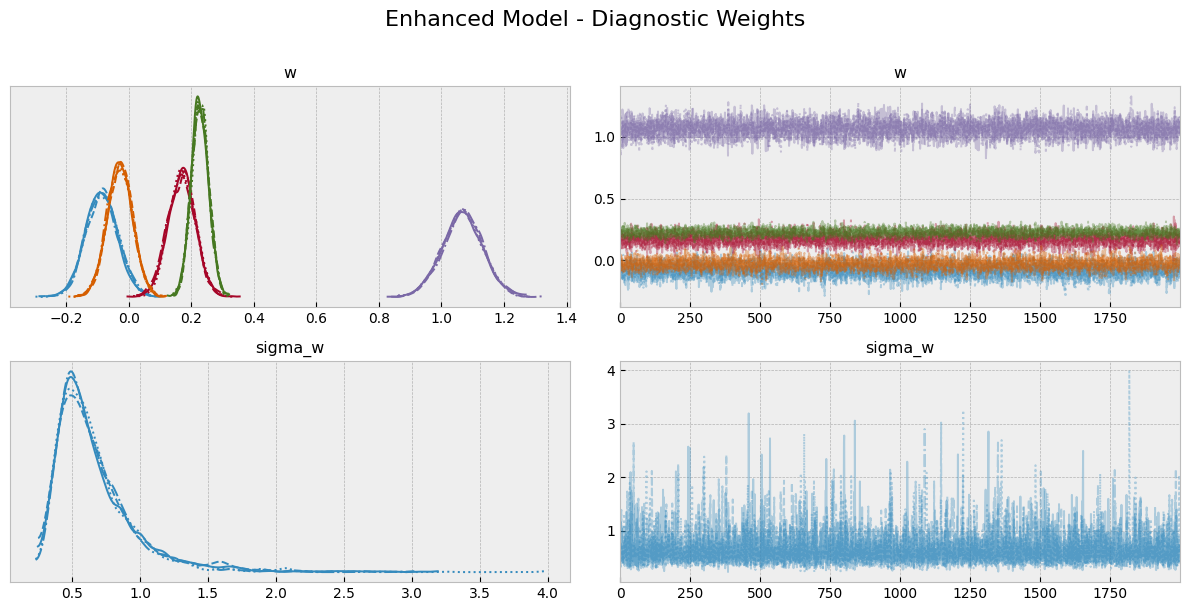

In [16]:
# Arviz trace for w and sigma_w
az.plot_trace(az_en, var_names=["w", "sigma_w"], compact=True, figsize=(12, 6))
plt.suptitle("Enhanced Model - Diagnostic Weights", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('../docs/figures/fig_enhanced_weights_trace.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# Analyse weight significance
w_samples = np.array(samples_en["w"])  # (n_samples, 5)
feature_names = ['X1', 'X2', 'X3', 'X4', 'X5']

print("Enhanced Model — Diagnostic Weight Summary:")
print(f"{'Feature':<10} {'Mean':>10} {'Std':>10} {'P(w>0)':>10}")
print("-" * 42)
for j, name in enumerate(feature_names):
    w_j = w_samples[:, j]
    print(f"{name:<10} {np.mean(w_j):>10.4f} {np.std(w_j):>10.4f} {np.mean(w_j > 0):>10.3f}")

Enhanced Model — Diagnostic Weight Summary:
Feature          Mean        Std     P(w>0)
------------------------------------------
X1            -0.0864     0.0515      0.051
X2             0.1686     0.0437      1.000
X3             1.0674     0.0646      1.000
X4             0.2271     0.0277      1.000
X5            -0.0290     0.0407      0.236


In [18]:
# Prediction function for enhanced model
def predict_enhanced(comp_idx, t_pred, samples, X_features):
    """
    Compute posterior predictive for enhanced model.
    Returns: f_mean, f_std, f_std_noisy, F (all function samples)
    """
    u_samples = samples["u_i"][:, comp_idx]  # (n_samples,)
    v_samples = samples["v_i"][:, comp_idx]
    w_samples = samples["w"]                  # (n_samples, 5)
    sigma_y_samples = samples["sigma_y"]

    x_i = X_features[comp_idx]  # (5,)
    wx = jnp.dot(w_samples, x_i)  # (n_samples,)

    t_pred = jnp.array(t_pred).reshape(1, -1)  # (1, T)

    effective_decay = (v_samples + wx).reshape(-1, 1)  # (n_samples, 1)
    F = u_samples.reshape(-1, 1) * jnp.exp(-effective_decay * t_pred / 100.0)  # (n_samples, T)

    f_mean = jnp.mean(F, axis=0)
    f_var = jnp.var(F, axis=0)
    f_std = jnp.sqrt(f_var)

    noise_var = jnp.mean(sigma_y_samples ** 2)
    f_std_noisy = jnp.sqrt(f_var + noise_var)

    return f_mean, f_std, f_std_noisy, F

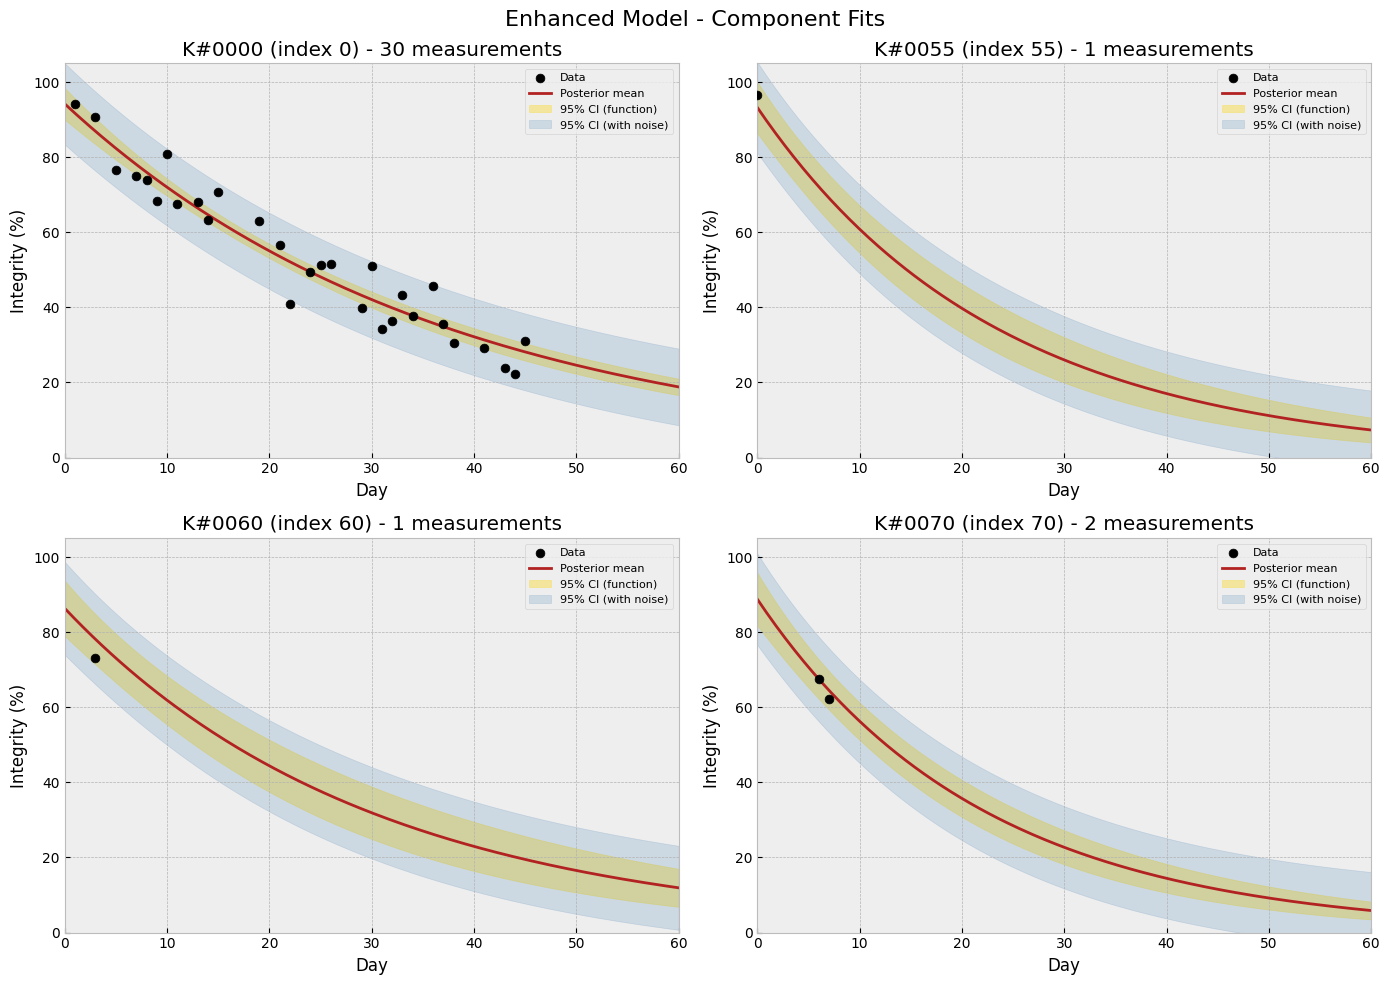

In [19]:
# Plot enhanced model fits for 4 components
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, comp_idx in zip(axes.ravel(), components_to_plot):
    comp_data = df[df['index'] == comp_idx]
    comp_id = comp_data['ID'].iloc[0]

    f_mean, f_std, f_std_noisy, _ = predict_enhanced(comp_idx, t_plot, samples_en, X_features)

    ax.scatter(comp_data['day'], comp_data['integrity'], s=40, zorder=5,
               color='black', label='Data')
    ax.plot(t_plot, f_mean, color='firebrick', lw=2, label='Posterior mean')
    ax.fill_between(t_plot, f_mean - 1.96 * f_std, f_mean + 1.96 * f_std,
                    alpha=0.35, color='gold', label='95% CI (function)')
    ax.fill_between(t_plot, f_mean - 1.96 * f_std_noisy, f_mean + 1.96 * f_std_noisy,
                    alpha=0.2, color='steelblue', label='95% CI (with noise)')

    ax.set_xlim(0, 60); ax.set_ylim(0, 105)
    ax.set_xlabel('Day'); ax.set_ylabel('Integrity (%)')
    ax.set_title(f"{comp_id} (index {comp_idx}) - {len(comp_data)} measurements")
    ax.legend(fontsize=8)

plt.suptitle("Enhanced Model - Component Fits", fontsize=16)
plt.tight_layout()
plt.savefig('../docs/figures/fig_enhanced_fits.png', dpi=150, bbox_inches='tight')
plt.show()

----
## 4. Blind Test Predictions

For components 50-74, predict P(integrity ≤ 30 at t=30) using the enhanced model.

Method: count the fraction of sampled functions $f$ that predict $y \leq 30$ at $t=30$.

In [20]:
# Blind test predictions using enhanced model
predictions = []

for comp_idx in range(50, 75):
    comp_id = df[df['index'] == comp_idx]['ID'].iloc[0]

    # Get all function samples at t=30
    _, _, _, F = predict_enhanced(comp_idx, jnp.array([30.0]), samples_en, X_features)
    f_at_30 = F[:, 0]  # (n_samples,)

    # P(integrity <= 30) = fraction of samples where y <= 30
    # Observation noise is not added: we estimate P(f(30) <= 30) for the latent degradation curve
    prob = float(jnp.mean(f_at_30 <= 30.0))

    predictions.append({
        'ID': comp_id,
        'index': comp_idx,
        'probability': prob
    })

df_pred = pd.DataFrame(predictions)
print(df_pred.to_string(index=False))

    ID  index  probability
K#0050     50     0.104875
K#0051     51     1.000000
K#0052     52     1.000000
K#0053     53     0.425000
K#0054     54     0.001000
K#0055     55     0.904500
K#0056     56     1.000000
K#0057     57     0.000000
K#0058     58     1.000000
K#0059     59     0.603625
K#0060     60     0.295875
K#0061     61     0.000625
K#0062     62     0.026750
K#0063     63     0.000125
K#0064     64     0.000000
K#0065     65     0.998125
K#0066     66     1.000000
K#0067     67     1.000000
K#0068     68     0.023750
K#0069     69     0.999750
K#0070     70     0.998000
K#0071     71     0.933375
K#0072     72     0.046875
K#0073     73     0.979875
K#0074     74     0.000000


In [21]:
# Save predictions
df_pred.to_csv('../results/predictions.csv', index=False, float_format='%.6f')
print("Saved results/predictions.csv")
print()
# Verify format
print(open('../results/predictions.csv').read())

Saved predictions.csv

ID,index,probability
K#0050,50,0.104875
K#0051,51,1.000000
K#0052,52,1.000000
K#0053,53,0.425000
K#0054,54,0.001000
K#0055,55,0.904500
K#0056,56,1.000000
K#0057,57,0.000000
K#0058,58,1.000000
K#0059,59,0.603625
K#0060,60,0.295875
K#0061,61,0.000625
K#0062,62,0.026750
K#0063,63,0.000125
K#0064,64,0.000000
K#0065,65,0.998125
K#0066,66,1.000000
K#0067,67,1.000000
K#0068,68,0.023750
K#0069,69,0.999750
K#0070,70,0.998000
K#0071,71,0.933375
K#0072,72,0.046875
K#0073,73,0.979875
K#0074,74,0.000000



---
## 5. Deployable Model

Save the posterior samples needed for the deployable predictor.

In [22]:
# Save model parameters for deployable notebook
model_data = {
    'u_i': np.array(samples_en['u_i']),
    'v_i': np.array(samples_en['v_i']),
    'w': np.array(samples_en['w']),
    'sigma_y': np.array(samples_en['sigma_y']),
    'X_features': X_features,
}
np.savez('../results/model_samples.npz', **model_data)
print("Saved results/model_samples.npz")
print("Contents:")
for k, v in model_data.items():
    print(f"  {k}: {v.shape}")

Saved model_samples.npz
Contents:
  u_i: (8000, 75)
  v_i: (8000, 75)
  w: (8000, 5)
  sigma_y: (8000,)
  X_features: (75, 5)


---
## 6. Additional Figures

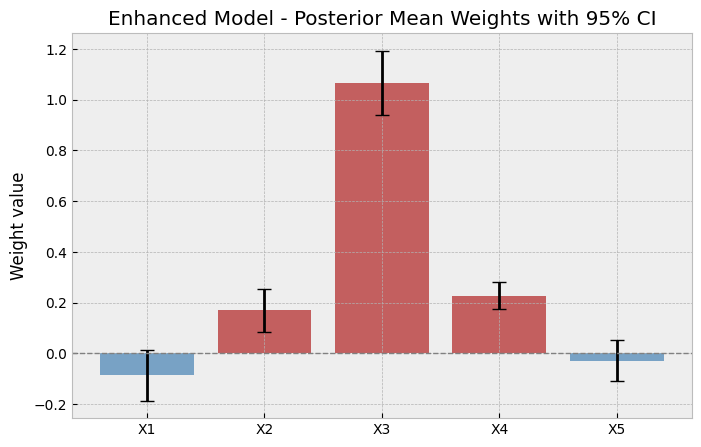

In [23]:
# Weight posterior distributions - bar chart
fig, ax = plt.subplots(figsize=(8, 5))
w_means = np.mean(w_samples, axis=0)
w_stds = np.std(w_samples, axis=0)
# Simple coloring based on significance
bar_colors = []
for m, s in zip(w_means, w_stds):
    if abs(m) > 1.5 * s and abs(m) > 0.1:
        bar_colors.append('firebrick')
    else:
        bar_colors.append('steelblue')

ax.bar(feature_names, w_means, yerr=1.96*w_stds, capsize=5, color=bar_colors, alpha=0.7)
ax.axhline(y=0, color='grey', ls='--', lw=1)
ax.set_ylabel('Weight value')
ax.set_title('Enhanced Model - Posterior Mean Weights with 95% CI')
plt.savefig('../docs/figures/fig_weight_bar.png', dpi=150, bbox_inches='tight')
plt.show()

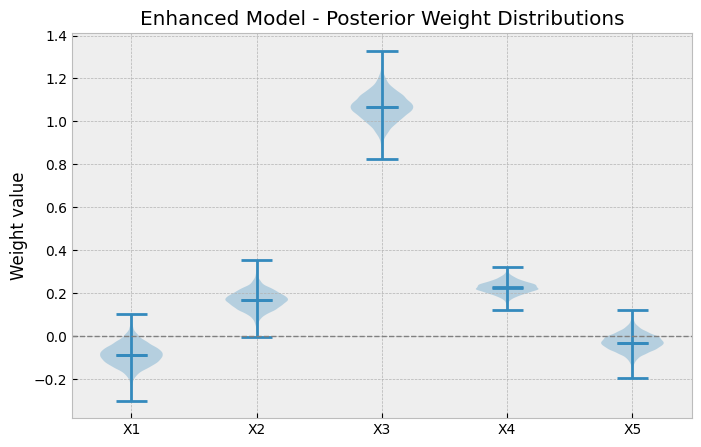

In [24]:
# Weight posterior violin plots
fig, ax = plt.subplots(figsize=(8, 5))
ax.violinplot(w_samples, positions=range(5), showmeans=True, showmedians=True)
ax.set_xticks(range(5))
ax.set_xticklabels(feature_names)
ax.axhline(y=0, color='grey', ls='--', lw=1)
ax.set_ylabel('Weight value')
ax.set_title('Enhanced Model - Posterior Weight Distributions')
plt.savefig('../docs/figures/fig_weight_violin.png', dpi=150, bbox_inches='tight')
plt.show()